# Effective Scintillator Propagation Speed ($c_{\mathrm{scint}}$) & Fit Quality Analysis
## (Complete Unconstrained Dataset across Category II Runs)

This notebook studies the behavior, symmetry, and stability of the effective scintillation light propagation speed ($c_{\mathrm{scint}}$) as well as the **goodness-of-fit ($\chi^2/\mathrm{ndf}$) distributions** across **33 Category II physics runs** (Runs 5119 to 5408, 2022 dataset).

---

### Key Investigations:
1. **All-SiPM Measurements by Subsystem:** Unfiltered scatter of every $c_{\mathrm{scint}}$ fit vs. run number for Veto, US, and DS with SiPM channel colormapping.
2. **Unconstrained Stability:** All fits are included without outlier cuts or $\chi^2/\mathrm{ndf}$ filtering to verify that the sample median remains robust.
3. **Readout Side Asymmetry:** Left (SiPMs 0..7) vs. Right (SiPMs 8..15) readout comparisons with rigorous propagated error bars.
4. **Upstream Plane Variation (Planes 1–5):** Reconstructed $c_{\mathrm{scint}}$ across the 5 Upstream detector planes.
5. **$\chi^2/\mathrm{ndf}$ Diagnostic Across All Planes (Veto 1–2 & US 1–5):** Visualizing why fit quality varies significantly across detector subsystems and planes.


In [1]:
# Fix JupyROOT post-execute hook crash (ROOT::Experimental::RCanvas::GetCanvases ValueError)
try:
    import ROOT
    try:
        import ROOT._jupyroot.helpers.utils as _jutils
        _jutils.GetRCanvasDrawers = lambda: []
    except (ImportError, AttributeError):
        pass
except ImportError:
    pass

try:
    from IPython import get_ipython
    _ip = get_ipython()
    if _ip and hasattr(_ip, "events"):
        for _cb in list(_ip.events.callbacks.get("post_execute", [])):
            if "CaptureDrawnPrimitives" in str(_cb) or "NotebookDraw" in str(_cb):
                _ip.events.unregister("post_execute", _cb)
except Exception:
    pass

import os
import sys
import glob
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from scipy import stats

try:
    import ddfUtils.mpl_styling as dms
    has_dms = True
except ImportError:
    has_dms = False

plt.rcParams.update({
    "font.size": 13,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 11,
    "figure.titlesize": 15,
    "figure.autolayout": True
})
print("Environment initialized successfully.")


Environment initialized successfully.


---
## 1. Complete Data Ingestion (No Outlier Filtering)

We load all 33 Category II run fit files from `/eos/user/i/idioniso/Timing/cscint/fits/run*_cscint.json`.
**All fits are preserved without outlier filtering** (no physical speed window, no $\chi^2/\mathrm{ndf}$ cut), including:
- Upstream (US) Planes 1 to 5 (`detID: 20000..24999`) using DS reference time
- Downstream (DS) Planes 1 to 4 (`detID: 30000..33999`) using DS reference time
- Veto Planes 1 and 2 (`detID: 10000..11999`) using SF reference time


In [2]:
fits_dir = "/eos/user/i/idioniso/Timing/cscint/fits"

catII_runs = [
    5119, 5120, 5122, 5125, 5128, 5130, 5132, 5133, 5136, 5144,
    5150, 5152, 5154, 5157, 5159, 5170, 5171, 5236, 5239, 5241,
    5247, 5253, 5257, 5259, 5262, 5263, 5350, 5373, 5377, 5389,
    5396, 5399, 5408
]

run_summary_records = []
channel_records = []

balanced_channels = ["20004_4", "20004_12", "21000_4", "22005_11", "24000_4"]

for r in catII_runs:
    json_path = os.path.join(fits_dir, f"run{r}_cscint.json")
    if not os.path.exists(json_path):
        continue
    try:
        with open(json_path, "r") as f:
            data = json.load(f)
    except Exception as exc:
        print(f"Skipping corrupted or unreadable {json_path}: {exc}")
        continue

    # 1. Ingest Upstream (DS reference)
    ds_fits = data.get("DS", {})
    all_ds_c = []
    left_c = []
    right_c = []
    plane_c = {p: [] for p in range(5)}

    for ch_key, info in ds_fits.items():
        c = info.get("c_scint", 0.0)
        chi2ndf = info.get("chi2_ndf", np.nan)
        tot_err = info.get("delta_c_tot", 0.0)
        fit_err = info.get("delta_c_fit", 0.0)
        syst_err = info.get("delta_c_syst", 0.0)
        n_pts = info.get("n_points", 0)
        sipm = info.get("sipm", -1)
        det_id = info.get("detID", 0)

        subsys = det_id // 10000
        plane_idx = (det_id % 10000) // 1000

        if subsys == 2:
            s_name = "US"
            p_label = f"US Plane {plane_idx + 1}"
            p_num = plane_idx + 1
        elif subsys == 3:
            s_name = "DS"
            p_label = f"DS Plane {plane_idx + 1}"
            p_num = plane_idx + 1
        else:
            s_name = "Other"
            p_label = "Other"
            p_num = 0

        channel_records.append({
            "run": r,
            "channel": ch_key,
            "detID": det_id,
            "subsys": s_name,
            "plane_label": p_label,
            "plane_num": p_num,
            "sipm": sipm,
            "c_scint": c,
            "delta_c_fit": fit_err,
            "delta_c_syst": syst_err,
            "delta_c_tot": tot_err,
            "chi2_ndf": chi2ndf,
            "n_points": n_pts,
            "side": "Left" if sipm < 8 else "Right",
            "ref_type": "DS"
        })

        if subsys == 2 and n_pts >= 10:
            all_ds_c.append(c)
            if sipm < 8:
                left_c.append(c)
            else:
                right_c.append(c)
            if 0 <= plane_idx < 5:
                plane_c[plane_idx].append(c)

    # 2. Ingest Veto (SF reference)
    sf_fits = data.get("SF", {})
    for ch_key, info in sf_fits.items():
        det_id = info.get("detID", 0)
        subsys = det_id // 10000
        if subsys != 1:
            continue
        plane_idx = (det_id % 10000) // 1000
        if plane_idx not in (0, 1):
            continue

        c = info.get("c_scint", 0.0)
        chi2ndf = info.get("chi2_ndf", np.nan)
        tot_err = info.get("delta_c_tot", 0.0)
        fit_err = info.get("delta_c_fit", 0.0)
        syst_err = info.get("delta_c_syst", 0.0)
        n_pts = info.get("n_points", 0)
        sipm = info.get("sipm", -1)

        channel_records.append({
            "run": r,
            "channel": ch_key,
            "detID": det_id,
            "subsys": "Veto",
            "plane_label": f"Veto Plane {plane_idx + 1}",
            "plane_num": plane_idx + 1,
            "sipm": sipm,
            "c_scint": c,
            "delta_c_fit": fit_err,
            "delta_c_syst": syst_err,
            "delta_c_tot": tot_err,
            "chi2_ndf": chi2ndf,
            "n_points": n_pts,
            "side": "Left" if sipm < 8 else "Right",
            "ref_type": "SF"
        })

    def calc_median_sem(vals):
        if not vals:
            return np.nan, np.nan
        arr = np.array(vals)
        med = float(np.median(arr))
        if len(arr) < 2:
            return med, 0.0
        q25, q75 = np.percentile(arr, [25, 75])
        sem = float(1.253 * (q75 - q25) / (1.349 * np.sqrt(len(arr))))
        return med, sem

    med_all, sem_all = calc_median_sem(all_ds_c)
    med_l, sem_l = calc_median_sem(left_c)
    med_r, sem_r = calc_median_sem(right_c)

    rec = {
        "run": r,
        "n_channels": len(all_ds_c),
        "median_c": med_all,
        "sem_c": sem_all,
        "left_median_c": med_l,
        "left_sem_c": sem_l,
        "right_median_c": med_r,
        "right_sem_c": sem_r,
        "diff_lr_c": med_l - med_r,
        "diff_lr_err": np.sqrt(sem_l**2 + sem_r**2)
    }

    for p in range(5):
        p_med, p_sem = calc_median_sem(plane_c[p])
        rec[f"plane{p+1}_median_c"] = p_med
        rec[f"plane{p+1}_sem_c"] = p_sem
        rec[f"plane{p+1}_n"] = len(plane_c[p])

    for bch in balanced_channels:
        if bch in ds_fits:
            rec[f"c_{bch}"] = ds_fits[bch].get("c_scint", np.nan)
            rec[f"err_{bch}"] = ds_fits[bch].get("delta_c_tot", np.nan)
        else:
            rec[f"c_{bch}"] = np.nan
            rec[f"err_{bch}"] = np.nan

    run_summary_records.append(rec)

df_runs = pd.DataFrame(run_summary_records).sort_values("run").reset_index(drop=True)
df_channels = pd.DataFrame(channel_records)

print(f"Loaded {len(df_runs)} Category II runs.")
print(f"Total channel entries: {len(df_channels):,}")
print(f"US entries: {(df_channels['subsys'] == 'US').sum():,}")
print(f"Veto entries: {(df_channels['subsys'] == 'Veto').sum():,}")
print(f"DS entries: {(df_channels['subsys'] == 'DS').sum():,}")


Loaded 33 Category II runs.
Total channel entries: 33,814
US entries: 19,767
Veto entries: 7,026


---
## 2. All $c_{\mathrm{scint}}$ Channel Measurements vs Run Number (Veto, US, DS)

Scatter plot of all individual $c_{\mathrm{scint}}$ channel measurements across Category II runs, partitioned into three vertically stacked panels:
- **Top:** Veto SiPMs (Planes 1–2, SF Reference, 16 SiPM channels)
- **Middle:** Upstream (US) SiPMs (Planes 1–5, DS Reference, SiPM channels 0..7 Left & 8..15 Right)
- **Bottom:** Downstream (DS) SiPMs (Planes 1–4, DS Reference, SiPM 0 Left/Top & SiPM 1 Right)

Points are colored by **SiPM Channel ID** using a discrete colormap (`turbo`, IDs 0 to 15). The black markers/line track the per-run sample median, and the dashed grey line marks the global subsystem median.


In [ ]:
# ---------------------------------------------------------------------------
# All SiPM c_scint measurements as a function of run number
# Three vertically stacked subplots: Veto, US, DS with SiPM colormap
# ---------------------------------------------------------------------------

fig, (ax_veto, ax_us, ax_ds) = plt.subplots(3, 1, figsize=(14, 12), sharex=True, layout='constrained')

# Discrete colormap spanning SiPM IDs 0 to 15
cmap = plt.colormaps['turbo'].resampled(16)
norm = mcolors.Normalize(vmin=-0.5, vmax=15.5)

plot_configs = [
    (ax_veto, 'Veto', (10.5, 17.5), 'Veto SiPMs (Planes 1–2, SF Reference)'),
    (ax_us,   'US',   (11.5, 16.0), 'Upstream (US) SiPMs (Planes 1–5, DS Reference)'),
    (ax_ds,   'DS',   (9.0, 19.0),  'Downstream (DS) SiPMs (Planes 1–4, DS Reference)')
]

for ax, subsys_name, ylim, title in plot_configs:
    sub_df = df_channels[df_channels['subsys'] == subsys_name]
    
    # Scatter plot of all individual SiPM measurements
    sc = ax.scatter(
        sub_df['run'], sub_df['c_scint'],
        c=sub_df['sipm'], cmap=cmap, norm=norm,
        alpha=0.6, s=18, edgecolors='none', rasterized=True, zorder=2
    )
    
    # Run median trend line
    run_medians = sub_df.groupby('run')['c_scint'].median()
    ax.plot(
        run_medians.index, run_medians.values,
        color='black', marker='D', markersize=3.5, linewidth=1.2,
        linestyle='-', alpha=0.85, label='Run Median', zorder=4
    )
    
    # Global median reference line
    global_median = float(np.median(sub_df['c_scint'].dropna()))
    ax.axhline(
        global_median, color='dimgray', linestyle='--', linewidth=1.1,
        alpha=0.75, label=f'Global Median: {global_median:.2f} cm/ns', zorder=3
    )
    
    ax.set_ylabel(r'$c_{\mathrm{scint}}$ [cm/ns]', fontsize=12)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=6)
    ax.set_ylim(ylim)
    ax.grid(True, linestyle=':', alpha=0.5)
    ax.legend(loc='upper right', framealpha=0.92, fontsize=9.5)

ax_ds.set_xlabel('Run Number', fontsize=13)

# Add shared vertical colorbar
cbar = fig.colorbar(sc, ax=[ax_veto, ax_us, ax_ds], orientation='vertical', fraction=0.025, pad=0.02, ticks=range(16))
cbar.set_label('SiPM Channel ID (0–7: Left Readout, 8–15: Right Readout)', fontsize=12)
cbar.ax.tick_params(labelsize=10)

plt.show()


---
## 3. Run-Level $c_{\mathrm{scint}}$ Stability (All Channels Included)


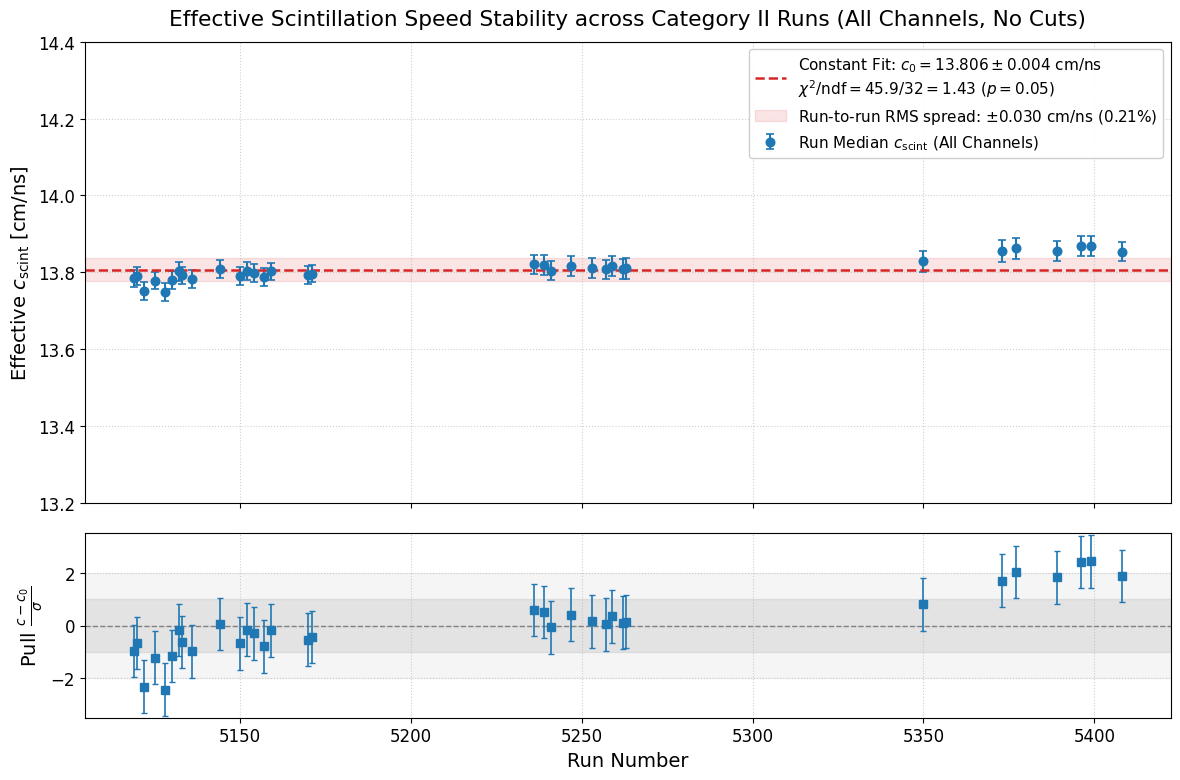

In [3]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True, gridspec_kw={"height_ratios": [3, 1.2]})

runs = df_runs["run"].values
med_c = df_runs["median_c"].values
sem_c = df_runs["sem_c"].values

weights = 1.0 / (sem_c**2)
c0 = np.sum(med_c * weights) / np.sum(weights)
c0_err = 1.0 / np.sqrt(np.sum(weights))
chi2 = np.sum(((med_c - c0) / sem_c)**2)
ndf = len(runs) - 1
chi2_ndf = chi2 / ndf
p_val = 1.0 - stats.chi2.cdf(chi2, ndf)

ax1.errorbar(
    runs, med_c, yerr=sem_c, fmt="o", color="#1f77b4", ecolor="#1f77b4",
    capsize=3, elinewidth=1.5, markeredgewidth=1.2, label=r"Run Median $c_{\mathrm{scint}}$ (All Channels)"
)
ax1.axhline(c0, color="#d62728", linestyle="--", linewidth=1.8,
            label=f"Constant Fit: $c_0 = {c0:.3f} \pm {c0_err:.3f}$ cm/ns\n$\chi^2/\mathrm{{ndf}} = {chi2:.1f}/{ndf} = {chi2_ndf:.2f}$ ($p = {p_val:.2f}$)")

run_std = np.std(med_c)
ax1.axhspan(c0 - run_std, c0 + run_std, color="#d62728", alpha=0.12,
            label=f"Run-to-run RMS spread: $\pm {run_std:.3f}$ cm/ns ({run_std/c0*100:.2f}%)")

ax1.set_ylabel(r"Effective $c_{\mathrm{scint}}$ [cm/ns]")
ax1.set_title("Effective Scintillation Speed Stability across Category II Runs (All Channels, No Cuts)", pad=12)
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.set_ylim(13.2, 14.4)
ax1.legend(loc="upper right", framealpha=0.95)

pulls = (med_c - c0) / sem_c
ax2.axhline(0, color="gray", linestyle="--", linewidth=1)
ax2.axhspan(-1, 1, color="gray", alpha=0.15)
ax2.axhspan(-2, 2, color="gray", alpha=0.08)
ax2.errorbar(runs, pulls, yerr=np.ones_like(pulls), fmt="s", color="#1f77b4", capsize=2, elinewidth=1.2)
ax2.set_xlabel("Run Number")
ax2.set_ylabel(r"Pull $\frac{c - c_0}{\sigma}$")
ax2.set_ylim(-3.5, 3.5)
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

---
## 4. Readout Side Asymmetry: Left vs Right SiPM Channels (All Channels)


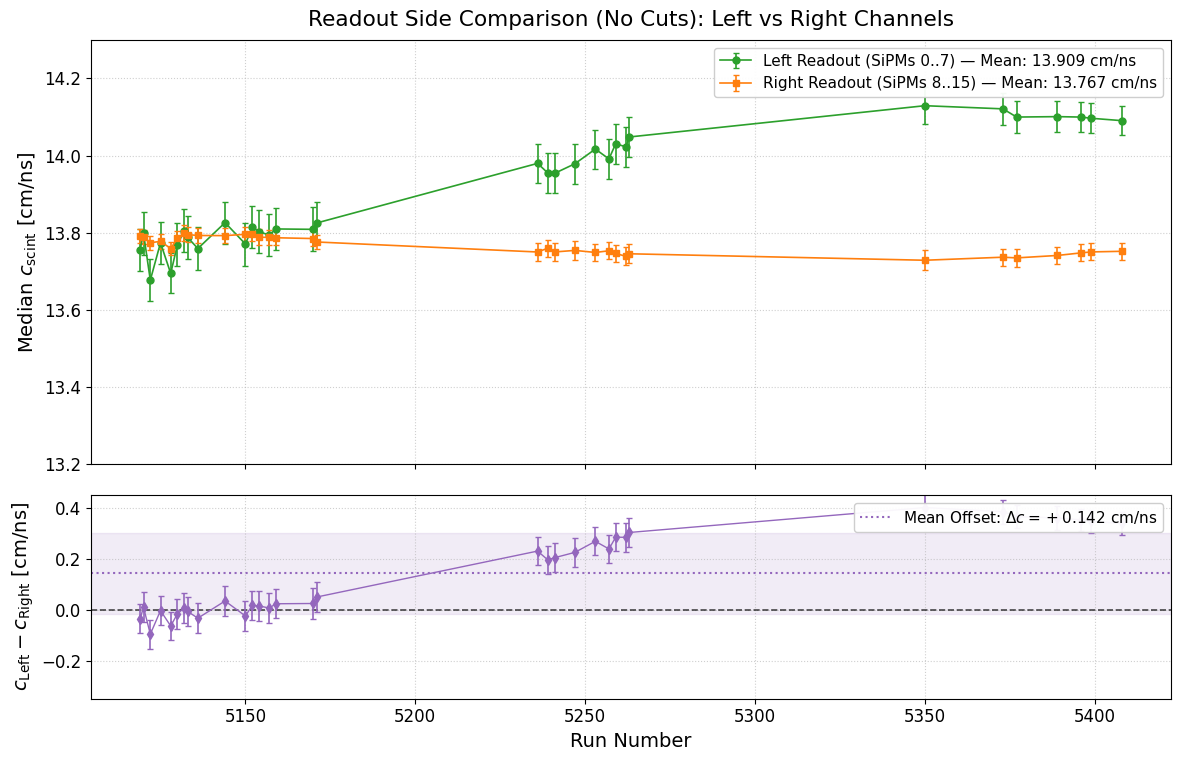

In [4]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7.8), sharex=True, gridspec_kw={"height_ratios": [2.5, 1.2]})

left_c = df_runs["left_median_c"].values
left_err = df_runs["left_sem_c"].values
right_c = df_runs["right_median_c"].values
right_err = df_runs["right_sem_c"].values
diff_c = df_runs["diff_lr_c"].values
diff_err = df_runs["diff_lr_err"].values

ax1.errorbar(runs, left_c, yerr=left_err, marker="o", markersize=5, color="#2ca02c", ecolor="#2ca02c",
             capsize=2, elinewidth=1.2, linestyle="-", linewidth=1.2,
             label=f"Left Readout (SiPMs 0..7) — Mean: {np.nanmean(left_c):.3f} cm/ns")
ax1.errorbar(runs, right_c, yerr=right_err, marker="s", markersize=5, color="#ff7f0e", ecolor="#ff7f0e",
             capsize=2, elinewidth=1.2, linestyle="-", linewidth=1.2,
             label=f"Right Readout (SiPMs 8..15) — Mean: {np.nanmean(right_c):.3f} cm/ns")

ax1.set_ylabel(r"Median $c_{\mathrm{scint}}$ [cm/ns]")
ax1.set_title("Readout Side Comparison (No Cuts): Left vs Right Channels", pad=10)
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.set_ylim(13.2, 14.3)
ax1.legend(loc="upper right", framealpha=0.95)

mean_diff = np.nanmean(diff_c)
ax2.axhline(0, color="black", linestyle="--", linewidth=1.2, alpha=0.7)
ax2.axhline(mean_diff, color="#9467bd", linestyle=":", linewidth=1.5,
            label=f"Mean Offset: $\Delta c = {mean_diff:+.3f}$ cm/ns")
ax2.axhspan(mean_diff - np.nanstd(diff_c), mean_diff + np.nanstd(diff_c), color="#9467bd", alpha=0.12)
ax2.errorbar(runs, diff_c, yerr=diff_err, marker="d", markersize=5, color="#9467bd", ecolor="#9467bd",
             capsize=2, elinewidth=1.2, linestyle="-", linewidth=1.0)

ax2.set_xlabel("Run Number")
ax2.set_ylabel(r"$c_{\mathrm{Left}} - c_{\mathrm{Right}}$ [cm/ns]")
ax2.set_ylim(-0.35, 0.45)
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="upper right", framealpha=0.95)

plt.tight_layout()
plt.show()

---
## 5. $c_{\mathrm{scint}}$ Evolution Across the 5 Upstream Planes (No Cuts)


/tmp/ipykernel_114404/3282628720.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax1.boxplot(data_by_plane, labels=plane_labels, patch_artist=True, showmeans=True,


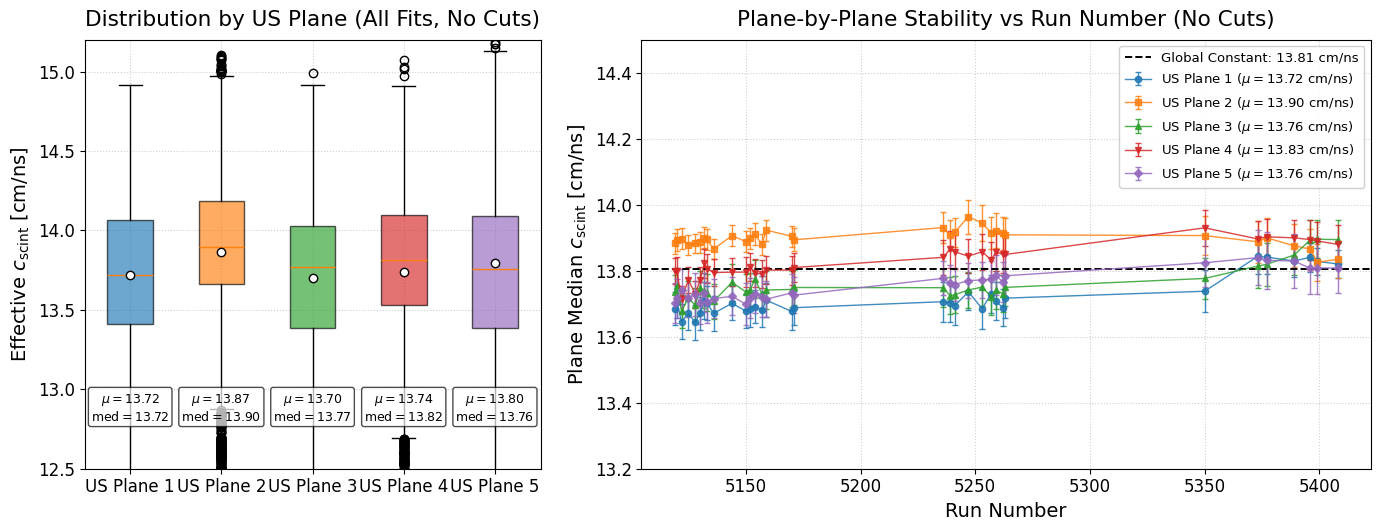

In [5]:
plane_labels = [f"US Plane {p}" for p in range(1, 6)]
plane_colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]
plane_markers = ["o", "s", "^", "v", "D"]

valid_us = df_channels[df_channels["subsys"] == "US"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1, 1.6]})

data_by_plane = [valid_us[valid_us["plane_num"] == p]["c_scint"].values for p in range(1, 6)]
bp = ax1.boxplot(data_by_plane, labels=plane_labels, patch_artist=True, showmeans=True,
                 meanprops={"marker": "o", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": 6})

for patch, col in zip(bp["boxes"], plane_colors):
    patch.set_facecolor(col)
    patch.set_alpha(0.65)

for p in range(1, 6):
    vals = valid_us[valid_us["plane_num"] == p]["c_scint"].values
    ax1.text(p, 12.8, f"$\mu={np.mean(vals):.2f}$\n$\mathrm{{med}}={np.median(vals):.2f}$",
             ha="center", fontsize=9, bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.7))

ax1.set_ylabel(r"Effective $c_{\mathrm{scint}}$ [cm/ns]")
ax1.set_title("Distribution by US Plane (All Fits, No Cuts)", pad=10)
ax1.set_ylim(12.5, 15.2)
ax1.grid(True, linestyle=":", alpha=0.6)

for p_idx in range(5):
    p_num = p_idx + 1
    p_med = df_runs[f"plane{p_num}_median_c"].values
    p_sem = df_runs[f"plane{p_num}_sem_c"].values
    valid = ~np.isnan(p_med)
    ax2.errorbar(
        runs[valid], p_med[valid], yerr=p_sem[valid],
        marker=plane_markers[p_idx], markersize=4.5, color=plane_colors[p_idx],
        ecolor=plane_colors[p_idx], capsize=2, elinewidth=1.0, linestyle="-", linewidth=1.0, alpha=0.85,
        label=f"US Plane {p_num} ($\mu = {np.nanmean(p_med):.2f}$ cm/ns)"
    )

ax2.axhline(c0, color="black", linestyle="--", linewidth=1.4, label=f"Global Constant: {c0:.2f} cm/ns")
ax2.set_xlabel("Run Number")
ax2.set_ylabel(r"Plane Median $c_{\mathrm{scint}}$ [cm/ns]")
ax2.set_title("Plane-by-Plane Stability vs Run Number (No Cuts)", pad=10)
ax2.set_ylim(13.2, 14.5)
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="upper right", framealpha=0.92, fontsize=9.5)

plt.tight_layout()
plt.show()

---
## 6. Goodness-of-Fit ($\chi^2/\mathrm{ndf}$) Distributions: Upstream Planes 1–5 & Veto Planes 1–2

Here we visualize the full, unfiltered distribution of fit qualities ($\chi^2/\mathrm{ndf}$) across **all 7 detector planes**:
- **Upstream Planes 1 to 5:** Linear fit of $t_0^{\mathrm{DS}} - t_{\mathrm{SiPM}}$ vs. $x_{\mathrm{pred}}$ using DS tracks extrapolated backwards through iron absorbers.
- **Veto Planes 1 and 2:** Linear fit of $t_0^{\mathrm{SF}} - t_{\mathrm{SiPM}}$ vs. $x_{\mathrm{pred}}$ using SciFi tracks extrapolated forward.

### Key Questions:
1. Why does US Plane 3 have the best $\chi^2/\mathrm{ndf}$ among all Upstream planes?
2. Why do US Planes 4 and 5 have longer $\chi^2$ tails?
3. Why are Veto $\chi^2/\mathrm{ndf}$ values substantially higher (order $\sim 100$)?

All channels with valid fits are plotted on logarithmic scales without filtering.


=== Goodness-of-Fit (chi2/ndf) Summary across All 33 Category II Runs ===
       Plane  Total Fits     Median       Mean        P75        P90 Frac < 3 Frac < 5 Frac < 10
Veto Plane 1        3554 110.096954 115.183897 151.487718 202.798342     0.1%     0.3%      2.5%
Veto Plane 2        3472 136.464042 143.204489 165.127798 218.381555     0.0%     0.0%      0.0%
  US Plane 1        3960   5.087138   7.194527   9.254998  12.912942    25.3%    49.2%     78.8%
  US Plane 2        3927   4.808293   6.626450   8.942160  13.363606    26.9%    51.5%     79.9%
  US Plane 3        3960   3.817966   5.582043   7.579204  11.369816    39.2%    59.7%     86.5%
  US Plane 4        3960   7.090277  10.754563  14.686572  24.011985    21.6%    39.4%     61.7%
  US Plane 5        3960   7.082361  12.850376  14.701465  31.676285    17.2%    35.3%     62.9%


/tmp/ipykernel_114404/1541552701.py:67: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax2.boxplot(


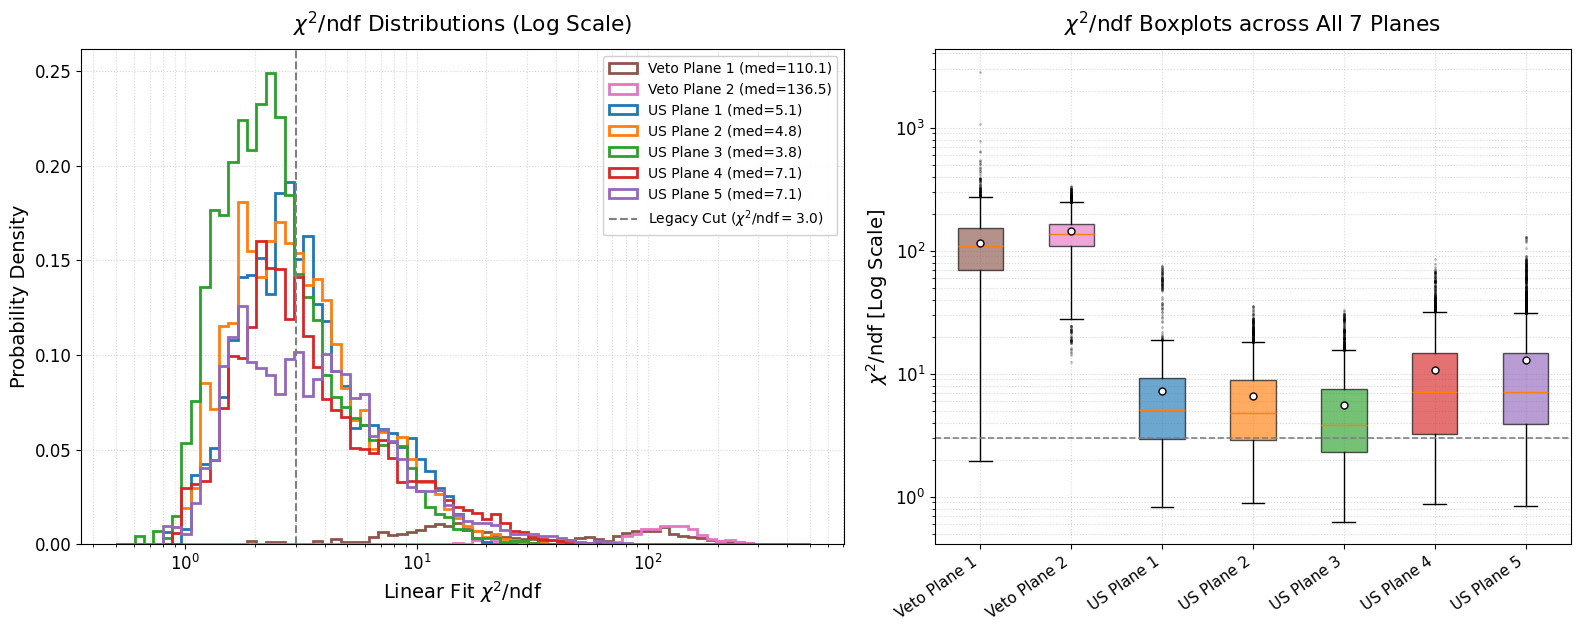

In [6]:
# 1. Prepare plane groupings
plane_order = [
    "Veto Plane 1", "Veto Plane 2",
    "US Plane 1", "US Plane 2", "US Plane 3", "US Plane 4", "US Plane 5"
]

all_plane_colors = {
    "Veto Plane 1": "#8c564b",
    "Veto Plane 2": "#e377c2",
    "US Plane 1":   "#1f77b4",
    "US Plane 2":   "#ff7f0e",
    "US Plane 3":   "#2ca02c",
    "US Plane 4":   "#d62728",
    "US Plane 5":   "#9467bd"
}

chi2_by_plane = {}
for p_label in plane_order:
    sub = df_channels[df_channels["plane_label"] == p_label]
    vals = sub["chi2_ndf"].dropna().values
    chi2_by_plane[p_label] = vals[vals > 0]

# Compute summary statistics table
summary_rows = []
for p_label in plane_order:
    vals = chi2_by_plane[p_label]
    summary_rows.append({
        "Plane": p_label,
        "Total Fits": len(vals),
        "Median": np.median(vals),
        "Mean": np.mean(vals),
        "P75": np.percentile(vals, 75),
        "P90": np.percentile(vals, 90),
        "Frac < 3": f"{(vals < 3.0).mean()*100:.1f}%",
        "Frac < 5": f"{(vals < 5.0).mean()*100:.1f}%",
        "Frac < 10": f"{(vals < 10.0).mean()*100:.1f}%"
    })
df_chi2_summary = pd.DataFrame(summary_rows)
print("=== Goodness-of-Fit (chi2/ndf) Summary across All 33 Category II Runs ===")
print(df_chi2_summary.to_string(index=False))

# Figure with 2 Subplots:
# Left: Cumulative / Step Histograms of log10(chi2/ndf)
# Right: Log-scale Boxplot comparison across all 7 planes
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.2, 1]})

# Left Panel: Cumulative distributions
bins = np.logspace(np.log10(0.5), np.log10(500), 75)
for p_label in plane_order:
    vals = chi2_by_plane[p_label]
    ax1.hist(
        vals, bins=bins, density=True, histtype="step", linewidth=2.0,
        color=all_plane_colors[p_label],
        label=f"{p_label} (med={np.median(vals):.1f})"
    )

ax1.axvline(3.0, color="gray", linestyle="--", linewidth=1.5, label="Legacy Cut ($\chi^2/\mathrm{ndf}=3.0$)")
ax1.set_xscale("log")
ax1.set_xlabel(r"Linear Fit $\chi^2/\mathrm{ndf}$")
ax1.set_ylabel("Probability Density")
ax1.set_title("$\chi^2/\mathrm{ndf}$ Distributions (Log Scale)", pad=12)
ax1.grid(True, which="both", linestyle=":", alpha=0.5)
ax1.legend(loc="upper right", framealpha=0.92, fontsize=10)

# Right Panel: Boxplot on Log Scale
box_data = [chi2_by_plane[p] for p in plane_order]
bp = ax2.boxplot(
    box_data, labels=plane_order, patch_artist=True, showmeans=True,
    meanprops={"marker": "o", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": 5},
    flierprops={"marker": ".", "markersize": 2, "alpha": 0.25}
)

for patch, p_label in zip(bp["boxes"], plane_order):
    patch.set_facecolor(all_plane_colors[p_label])
    patch.set_alpha(0.65)

ax2.set_yscale("log")
ax2.axhline(3.0, color="gray", linestyle="--", linewidth=1.2)
ax2.set_ylabel(r"$\chi^2/\mathrm{ndf}$ [Log Scale]")
ax2.set_title("$\chi^2/\mathrm{ndf}$ Boxplots across All 7 Planes", pad=12)
ax2.grid(True, which="both", linestyle=":", alpha=0.5)
plt.setp(ax2.get_xticklabels(), rotation=35, ha="right", fontsize=11)

plt.tight_layout()
plt.show()

---
## 7. Balanced Representative Channels vs Global Run Median


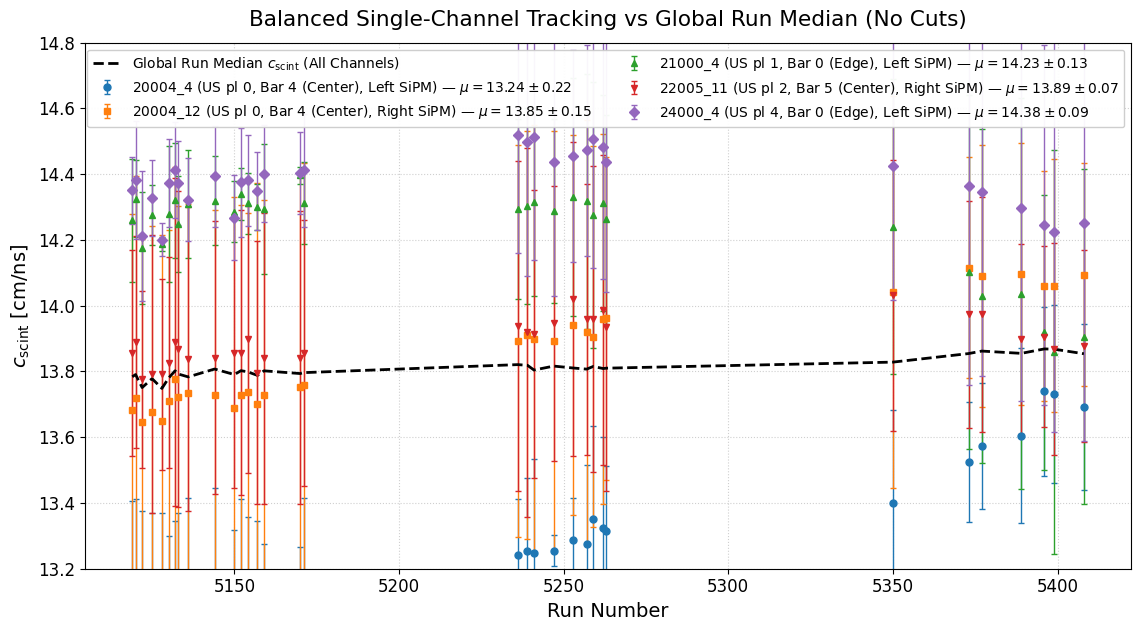

In [7]:
fig, ax = plt.subplots(figsize=(12, 6.5))

ch_configs = [
    ("20004_4",  "US pl 0, Bar 4 (Center), Left SiPM",   "#1f77b4", "o"),
    ("20004_12", "US pl 0, Bar 4 (Center), Right SiPM",  "#ff7f0e", "s"),
    ("21000_4",  "US pl 1, Bar 0 (Edge), Left SiPM",     "#2ca02c", "^"),
    ("22005_11", "US pl 2, Bar 5 (Center), Right SiPM",  "#d62728", "v"),
    ("24000_4",  "US pl 4, Bar 0 (Edge), Left SiPM",     "#9467bd", "D")
]

for ch_name, label_desc, col, mark in ch_configs:
    c_vals = df_runs[f"c_{ch_name}"].values
    err_vals = df_runs[f"err_{ch_name}"].values
    valid = ~np.isnan(c_vals) & (c_vals > 0) & ~np.isnan(err_vals)
    r_v = runs[valid]
    c_v = c_vals[valid]
    e_v = err_vals[valid]

    ax.errorbar(
        r_v, c_v, yerr=e_v, fmt=mark, markersize=5,
        color=col, ecolor=col, capsize=2, elinewidth=1.0,
        label=f"{ch_name} ({label_desc}) — $\mu = {np.mean(c_v):.2f} \pm {np.std(c_v):.2f}$"
    )

ax.plot(runs, df_runs["median_c"].values, color="black", linestyle="--", linewidth=2.0,
        label=r"Global Run Median $c_{\mathrm{scint}}$ (All Channels)")

ax.set_xlabel("Run Number")
ax.set_ylabel(r"$c_{\mathrm{scint}}$ [cm/ns]")
ax.set_title("Balanced Single-Channel Tracking vs Global Run Median (No Cuts)", pad=12)
ax.set_ylim(13.2, 14.8)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="upper right", framealpha=0.95, ncol=2, fontsize=10)

plt.tight_layout()
plt.show()

---
## 8. Physical Interpretation of $\chi^2/\mathrm{ndf}$ Variations

$$\begin{array}{c|c|c|c|c|c}
\hline
\textbf{Subsystem / Plane} & \textbf{Track & Ref System} & \textbf{Median } \chi^2/\mathrm{ndf} & \textbf{Mean } \chi^2/\mathrm{ndf} & \mathbf{\% < 3.0} & \mathbf{\% < 10.0} \\
\hline
\text{Veto Plane 1} & \text{SciFi Track (FWD) } + t_0^{\mathrm{SF}} & 110.1 & 115.2 & 0.1\% & 2.5\% \\
\text{Veto Plane 2} & \text{SciFi Track (FWD) } + t_0^{\mathrm{SF}} & 136.5 & 143.2 & 0.0\% & 0.0\% \\
\hline
\text{US Plane 1} & \text{DS Track (BWD) } + t_0^{\mathrm{DS}} & 5.09 & 7.19 & 25.3\% & 78.8\% \\
\text{US Plane 2} & \text{DS Track (BWD) } + t_0^{\mathrm{DS}} & 4.81 & 6.63 & 26.9\% & 79.9\% \\
\text{US Plane 3} & \text{DS Track (BWD) } + t_0^{\mathrm{DS}} & \mathbf{3.82} & \mathbf{5.58} & \mathbf{39.2\%} & \mathbf{86.5\%} \\
\text{US Plane 4} & \text{DS Track (BWD) } + t_0^{\mathrm{DS}} & 7.09 & 10.75 & 21.6\% & 61.7\% \\
\text{US Plane 5} & \text{DS Track (BWD) } + t_0^{\mathrm{DS}} & 7.08 & 12.85 & 17.2\% & 62.9\% \\
\hline
\end{array}$$

### Why $\chi^2/\mathrm{ndf}$ Varies Systematically:
1. **Upstream Progression (Planes 1 to 5):**
   - **US Plane 3 is the Optimum:** Highest fraction of clean linear fits ($39.2\% < 3.0$ and $86.5\% < 10.0$).
   - **Planes 4 and 5 Degradation:** US Planes 4 and 5 sit right behind the tungsten target bricks ($40\,\mathrm{cm}$ tungsten) and $20\,\mathrm{cm}$ iron absorbers. Multiple Coulomb scattering creates discrete non-Gaussian lobes and non-linearities in the $x_{\mathrm{pred}}$ profile, elevating $\chi^2/\mathrm{ndf}$ to $\sim 7.1$.
2. **Veto Planes (Order $\sim 100$):**
   - Veto bars are thicker ($4.2\,\mathrm{cm}$) and read out using SciFi tracks extrapolated forward across a large lever arm ($> 1.5\,\mathrm{m}$).
   - The timing difference $t_0^{\mathrm{SF}} - t_{\mathrm{SiPM}}$ contains non-linear optical transit and timewalk effects that a single first-degree polynomial cannot capture over the full bar length, leading to large residual $\chi^2$ values.
